In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# find the repo root no matter where the kernel was started
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

RESULTS = ROOT / "benchmarks" / "results"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def load_records(*names):
    """Load benchmark records produced by scripts/benchmark.py."""
    recs = []
    for name in names:
        with open(RESULTS / (name + ".json")) as f:
            recs.extend(json.load(f)["records"])
    return pd.DataFrame(recs)

def save_fig(fig, filename):
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight")
    print("saved reports/figures/" + filename)


=== Aggregate benchmark summary ===


runs  aggregate_tok_s  mean_run_tok_s  \
experiment   mode                                                 
QA K=2 (E)   baseline       15           73.814          74.741   
             speculative    15           77.170          77.945   
QA K=4 (F)   baseline       15           43.602          52.743   
             speculative    15           40.745          48.387   
Full K=2 (G) baseline       60           76.525          76.788   
             speculative    60           75.708          76.654   

                          p50_latency_s  p95_latency_s  mean_ttft_s  \
experiment   mode                                                     
QA K=2 (E)   baseline             0.819          1.079        0.017   
             speculative          0.802          0.972        0.062   
QA K=4 (F)   baseline             1.846          2.008        0.041   
             speculative          1.789          2.478        0.144   
Full K=2 (G) baseline             0.817          0.938        0.021   
             speculative          0.829          0.992        0.071   

                          acceptance_rate  
experiment   mode                          
QA K=2 (E)   baseline                 NaN  
             speculative            0.779  
QA K=4 (F)   baseline                 NaN  
             speculative            0.596  
Full K=2 (G) baseline                 NaN  
             speculative            0.756

saved reports/figures/xpu_aggregate_throughput.png


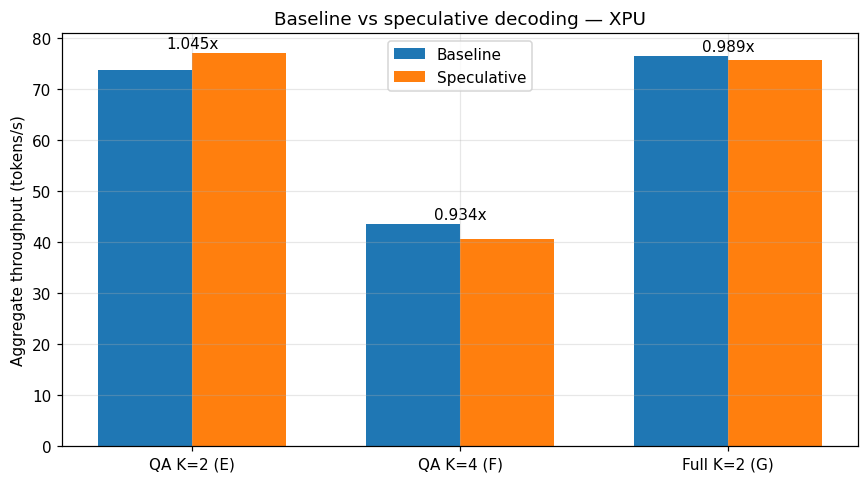


Speedup > 1.0x means speculative decoding is faster.
QA K=2 (E)      : 1.045x
QA K=4 (F)      : 0.934x
Full K=2 (G)    : 0.989x

=== Experiment G: paired prompt results ===


,median_speedup,mean_speedup,wins,runs
prompt_id,,,,
expl-gravity,0.849,0.886,0,5
code-reverse,0.885,0.900,1,5
code-class,0.939,0.962,1,5
qa-photosynthesis,0.958,0.971,1,5
sum-science,0.966,0.955,1,5
expl-compound-interest,0.993,1.011,2,5
expl-neural-net,1.001,0.989,3,5
code-fibonacci,1.042,1.004,4,5
qa-history,1.062,1.037,4,5


Overall paired median: 1.001x
Paired wins: 31/60
saved reports/figures/xpu_per_prompt_speedup.png


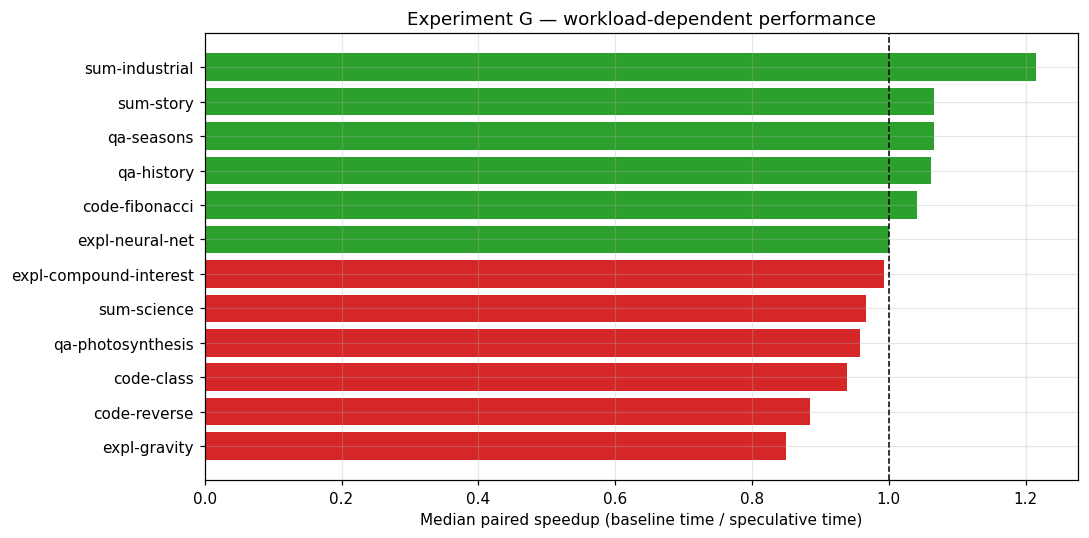

mode,baseline,speculative
p50_latency_s,0.817,0.829
p95_latency_s,0.938,0.992


saved reports/figures/xpu_latency.png


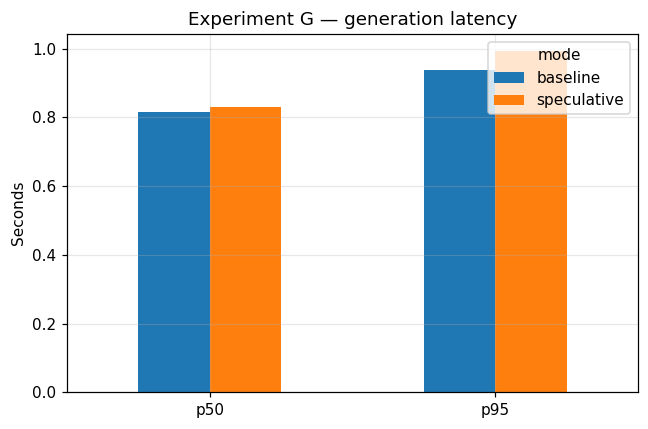

In [2]:
# Load corrected, interleaved XPU experiments.
expE = load_records("expE_interleaved_qa_K2_xpu_float32")
expF = load_records("expF_interleaved_qa_K4_xpu_float32")
expG = load_records("expG_interleaved_full_K2_xpu_float32")

experiments = {
    "QA K=2 (E)": expE,
    "QA K=4 (F)": expF,
    "Full K=2 (G)": expG,
}


def summarize_runs(df):
    total_time = df["wall_time"].sum()
    total_tokens = df["new_tokens"].sum()

    proposed = df["proposed"].sum()
    accepted = df["accepted"].sum()

    return {
        "runs": len(df),
        "aggregate_tok_s": total_tokens / total_time if total_time else 0,
        "mean_run_tok_s": df["tokens_per_sec"].mean(),
        "p50_latency_s": df["wall_time"].median(),
        "p95_latency_s": df["wall_time"].quantile(0.95),
        "mean_ttft_s": df["ttft"].mean(),
        "acceptance_rate": accepted / proposed if proposed else np.nan,
    }


# 1. Aggregate summary
summary_rows = []

for experiment, df in experiments.items():
    for mode in ("baseline", "speculative"):
        subset = df[df["mode"] == mode]
        result = summarize_runs(subset)
        result.update({"experiment": experiment, "mode": mode})
        summary_rows.append(result)

summary_df = pd.DataFrame(summary_rows).set_index(["experiment", "mode"])

print("=== Aggregate benchmark summary ===")
display(summary_df.round(3))


# 2. Aggregate throughput comparison
labels = []
baseline_tps = []
speculative_tps = []
speedups = []

for experiment, df in experiments.items():
    b = summarize_runs(df[df["mode"] == "baseline"])["aggregate_tok_s"]
    s = summarize_runs(df[df["mode"] == "speculative"])["aggregate_tok_s"]

    labels.append(experiment)
    baseline_tps.append(b)
    speculative_tps.append(s)
    speedups.append(s / b if b else np.nan)

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width / 2, baseline_tps, width, label="Baseline")
ax.bar(x + width / 2, speculative_tps, width, label="Speculative")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Aggregate throughput (tokens/s)")
ax.set_title("Baseline vs speculative decoding — XPU")
ax.legend()

for i, speedup in enumerate(speedups):
    ax.text(
        i, max(baseline_tps[i], speculative_tps[i]) + 1,
        f"{speedup:.3f}x", ha="center"
    )

fig.tight_layout()
save_fig(fig, "xpu_aggregate_throughput.png")
plt.show()

print("\nSpeedup > 1.0x means speculative decoding is faster.")
for label, speedup in zip(labels, speedups):
    print(f"{label:16s}: {speedup:.3f}x")


# 3. Paired prompt analysis for the full-workload experiment
baseline = expG[expG["mode"] == "baseline"][
    ["prompt_id", "rep", "wall_time"]
].rename(columns={"wall_time": "baseline_time"})

speculative = expG[expG["mode"] == "speculative"][
    ["prompt_id", "rep", "wall_time"]
].rename(columns={"wall_time": "speculative_time"})

paired = baseline.merge(
    speculative, on=["prompt_id", "rep"], validate="one_to_one"
)

paired["speedup"] = paired["baseline_time"] / paired["speculative_time"]

prompt_summary = paired.groupby("prompt_id")["speedup"].agg(
    median_speedup="median",
    mean_speedup="mean",
    wins=lambda values: int((values > 1).sum()),
    runs="count",
).sort_values("median_speedup")

print("\n=== Experiment G: paired prompt results ===")
display(prompt_summary.round(3))

print(
    f"Overall paired median: {paired['speedup'].median():.3f}x"
)
print(
    f"Paired wins: {(paired['speedup'] > 1).sum()}/{len(paired)}"
)

fig, ax = plt.subplots(figsize=(10, 5))
colors = [
    "tab:green" if value > 1 else "tab:red"
    for value in prompt_summary["median_speedup"]
]

ax.barh(
    prompt_summary.index,
    prompt_summary["median_speedup"],
    color=colors,
)
ax.axvline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Median paired speedup (baseline time / speculative time)")
ax.set_title("Experiment G — workload-dependent performance")
fig.tight_layout()
save_fig(fig, "xpu_per_prompt_speedup.png")
plt.show()


# 4. Latency comparison for Experiment G
g_summary = summary_df.loc["Full K=2 (G)"]

latency_metrics = ["p50_latency_s", "p95_latency_s"]
latency_data = g_summary.loc[
    ["baseline", "speculative"], latency_metrics
].T

display(latency_data.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
latency_data.plot(kind="bar", ax=ax)
ax.set_ylabel("Seconds")
ax.set_title("Experiment G — generation latency")
ax.set_xticklabels(["p50", "p95"], rotation=0)
fig.tight_layout()
save_fig(fig, "xpu_latency.png")
plt.show()